In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32,padding=4)
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

batch_size = 256

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 4 * 4, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        return self.model(x)


model = CNN()

num_epochs = 20
weight_decay = 0

criterion = nn.CrossEntropyLoss()


optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    weight_decay=weight_decay,
    momentum=0.9
)
scheduler=torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=20,
    gamma=0.1
)


train_loss_list = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_acc = 0


    print(f"Epoch {epoch+1}/{num_epochs}:", end=" ")

    for images, labels in train_loader:
        images = images
        y_true = labels
        outputs = model(images)
        _, y_pred = torch.max(outputs.data, 1)
        train_acc += (y_pred == y_true).sum().item()

        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
    scheduler.step()

    epoch_loss = train_loss / len(train_loader)
    train_loss_list.append(epoch_loss)

print(f"15th Epoch Training Loss = {train_loss_list[-1]:.4f}")
print(f"Train set accuracy = {100 * train_acc / len(train_dataset)} %")




100%|██████████| 170M/170M [00:02<00:00, 61.6MB/s]


Epoch 1/20: Epoch 2/20: Epoch 3/20: Epoch 4/20: Epoch 5/20: Epoch 6/20: Epoch 7/20: Epoch 8/20: Epoch 9/20: Epoch 10/20: Epoch 11/20: Epoch 12/20: Epoch 13/20: Epoch 14/20: Epoch 15/20: Epoch 16/20: Epoch 17/20: Epoch 18/20: Epoch 19/20: Epoch 20/20: 15th Epoch Training Loss = 0.6242
Train set accuracy = 77.89 %


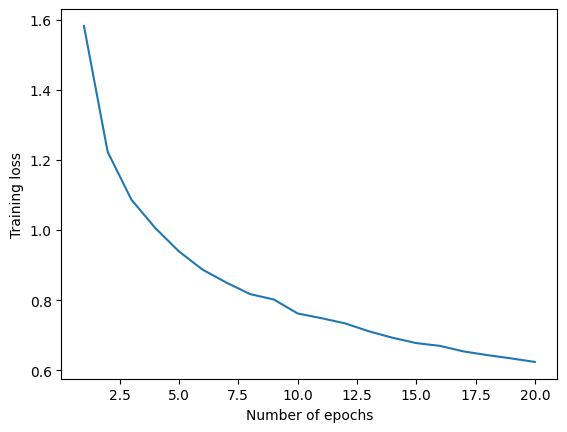

In [ ]:
import matplotlib.pyplot as plt
num_epochs=20
plt.plot(range(1, num_epochs + 1), train_loss_list)
plt.xlabel("Number of epochs")
plt.ylabel("Training loss")
plt.show()

In [ ]:
test_acc = 0
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images
        y_true = labels
        outputs = model(images)
        _, y_pred = torch.max(outputs.data, 1)
        test_acc += (y_pred == y_true).sum().item()

print(f"Test set accuracy = {100 * test_acc / len(test_dataset)} %")

Test set accuracy = 76.36 %


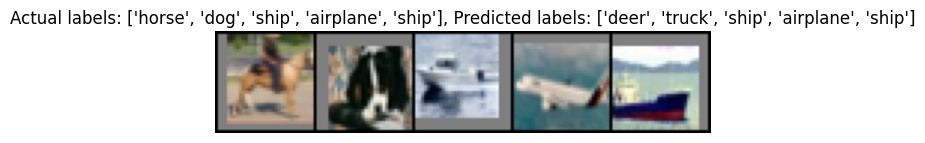

In [ ]:
num_images = 5
import numpy as np
names = list(test_dataset.class_to_idx.keys())
y_true_name = [names[y_true[idx]] for idx in range(num_images)]
y_pred_name = [names[y_pred[idx]] for idx in range(num_images)]
title = f"Actual labels: {y_true_name}, Predicted labels: {y_pred_name}"

plt.imshow(np.transpose(torchvision.utils.make_grid(
    images[:num_images].cpu(), normalize=True, padding=1).numpy(), (1, 2, 0)))
plt.title(title)
plt.axis("off")
plt.show()

In [ ]:
torch.save(model.state_dict(), "model.pth")
from google.colab import files
files.download("model.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
files.download('Untitled2.ipynb')

FileNotFoundError: Cannot find file: Untitled2.ipynb